In [10]:
# Part 0 — Setup and First Look
# Task 0.1 — Load and check the data 

import os, warnings
os.environ["LOKY_MAX_CPU_COUNT"] = "4"
warnings.filterwarnings("ignore", category=UserWarning)

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, silhouette_samples, adjusted_rand_score
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.datasets import load_wine

SEED = 42

df = pd.read_csv(r"C:\Users\M.LAPTOP\Desktop\ml lab10\archive (1)\Mall_Customers.csv").rename(
    columns={"Annual Income (k$)": "Income", "Spending Score (1-100)": "Spending"})
print("Shape:", df.shape)
print("Missing values:", df.isnull().sum().sum(), "| Duplicates:", df.duplicated().sum())
print(df["Gender"].value_counts())
display(df[["Age", "Income", "Spending"]].describe().round(2))

Shape: (200, 5)
Missing values: 0 | Duplicates: 0
Gender
Female    112
Male       88
Name: count, dtype: int64


,Age,Income,Spending
count,200.00,200.00,200.00
mean,38.85,60.56,50.20
std,13.97,26.26,25.82
min,18.00,15.00,1.00
25%,28.75,41.50,34.75
50%,36.00,61.50,50.00
75%,49.00,78.00,73.00
max,70.00,137.00,99.00


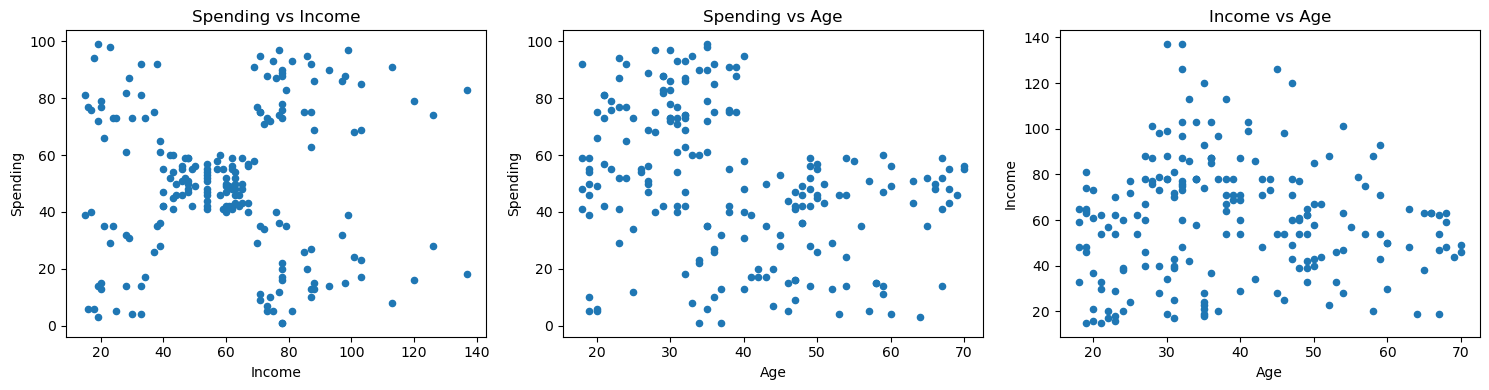

In [2]:
# Task 0.2 — Look at the data before clustering
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, (x, y) in zip(ax, [("Income", "Spending"), ("Age", "Spending"), ("Age", "Income")]):
    a.scatter(df[x], df[y], s=20)
    a.set_xlabel(x); a.set_ylabel(y); a.set_title(f"{y} vs {x}")
plt.tight_layout(); plt.show()

In [3]:
# (a) How many groups can you see by eye in each of the three plots? Which plot shows the groups most clearly? 
# Spending vs Income shows the clearest groups, about 5 (a central block plus four corners). Spending vs Age and Income vs Age
# show no clear groups.
# (b) Why can we not use accuracy or a train/test split to judge a clustering result? 
# There is no true label to compare with, so accuracy and train/test don’t exist. We judge clusters by tightness, separation
# (silhouette) and whether they make sense

In [4]:
# Part 1 — K-Means From Scratch
# Task 1.1 — Lecture Example 1 in code (one feature)
x = np.array([2, 4, 10, 12, 3, 20, 30, 11, 25], float)
m = np.array([4., 11.])
it = 0
while True:
    it += 1
    dist = np.abs(x[:, None] - m[None, :])          # shape (9, 2)
    lab = dist.argmin(axis=1)
    new = np.array([x[lab == k].mean() for k in range(2)])
    print(f"Iter {it}: C1={x[lab==0].tolist()}  C2={x[lab==1].tolist()}  new centroids={new.tolist()}")
    if np.allclose(new, m): break
    m = new
inertia = sum(((x[lab == k] - m[k]) ** 2).sum() for k in range(2))
print("Final centroids:", m, "| Inertia:", inertia)

Iter 1: C1=[2.0, 4.0, 3.0]  C2=[10.0, 12.0, 20.0, 30.0, 11.0, 25.0]  new centroids=[3.0, 18.0]
Iter 2: C1=[2.0, 4.0, 10.0, 3.0]  C2=[12.0, 20.0, 30.0, 11.0, 25.0]  new centroids=[4.75, 19.6]
Iter 3: C1=[2.0, 4.0, 10.0, 12.0, 3.0, 11.0]  C2=[20.0, 30.0, 25.0]  new centroids=[7.0, 25.0]
Iter 4: C1=[2.0, 4.0, 10.0, 12.0, 3.0, 11.0]  C2=[20.0, 30.0, 25.0]  new centroids=[7.0, 25.0]
Final centroids: [ 7. 25.] | Inertia: 150.0


In [5]:
# Task 1.2 — Lecture Example 2 in code (two features)
P = np.array([(185,72),(170,56),(168,60),(179,68),(182,72),(188,77)], float)
M = P[:2].copy()
it = 0
while True:
    it += 1
    d = np.sqrt(((P[:, None, :] - M[None, :, :]) ** 2).sum(axis=2))
    lab = d.argmin(axis=1)
    new = np.array([P[lab == k].mean(axis=0) for k in range(2)])
    print(f"Iter {it}: clusters={(lab+1).tolist()}  centroids={new.round(2).tolist()}")
    print(pd.DataFrame(d.round(2), columns=["d to M1", "d to M2"], index=[f"P{i+1}" for i in range(6)]))
    if np.allclose(new, M): break
    M = new

Iter 1: clusters=[1, 2, 2, 1, 1, 1]  centroids=[[183.5, 72.25], [169.0, 58.0]]
    d to M1  d to M2
P1     0.00    21.93
P2    21.93     0.00
P3    20.81     4.47
P4     7.21    15.00
P5     3.00    20.00
P6     5.83    27.66
Iter 2: clusters=[1, 2, 2, 1, 1, 1]  centroids=[[183.5, 72.25], [169.0, 58.0]]
    d to M1  d to M2
P1     1.52    21.26
P2    21.13     2.24
P3    19.76     2.24
P4     6.19    14.14
P5     1.52    19.10
P6     6.54    26.87


In [6]:
# Task 1.3 — Write your own K-Means function 
def my_kmeans(X, init_centroids, max_iter=100):
    X = np.asarray(X, float); C = np.asarray(init_centroids, float).copy()
    if X.ndim == 1: X = X.reshape(-1, 1)
    if C.ndim == 1: C = C.reshape(-1, 1)
    for it in range(1, max_iter + 1):
        d = np.sqrt(((X[:, None, :] - C[None, :, :]) ** 2).sum(axis=2))
        labels = d.argmin(axis=1)                                  # assign
        newC = C.copy()
        for k in range(len(C)):
            if (labels == k).any():                                # empty cluster: keep old centroid
                newC[k] = X[labels == k].mean(axis=0)              # update
        if np.allclose(newC, C): break                             # converged
        C = newC
    d = np.sqrt(((X[:, None, :] - C[None, :, :]) ** 2).sum(axis=2))
    labels = d.argmin(axis=1)
    inertia = ((X - C[labels]) ** 2).sum()
    return labels, C, inertia, it

l, C, I, n = my_kmeans(x, [4, 11])
print("Centroids:", C.ravel(), "| Inertia:", I, "| Iterations:", n)

Centroids: [ 7. 25.] | Inertia: 150.0 | Iterations: 4


In [11]:
# Task 1.4 — Check your function against scikit-learn 
X2 = df[["Income", "Spending"]].values
l1, C1, I1, n1 = my_kmeans(X2, X2[:5])
sk = KMeans(n_clusters=5, init=X2[:5], n_init=1, tol=0, algorithm="lloyd").fit(X2)
print("Mine:", n1, "iterations, inertia", round(I1, 4))
print("SKL :", sk.n_iter_, "iterations, inertia", round(sk.inertia_, 4))
print("Labels equal:", np.array_equal(l1, sk.labels_),
      "| Centroids close:", np.allclose(C1, sk.cluster_centers_),
      "| ARI:", adjusted_rand_score(l1, sk.labels_))

Mine: 4 iterations, inertia 44448.4554
SKL : 4 iterations, inertia 44448.4554
Labels equal: True | Centroids close: True | ARI: 1.0


In [12]:
# (a) Example 1: the point 10 started in cluster C2 but moved to C1 in iteration 2. Explain why, using the centroid values.
# In iteration 1 the centroids are 4 and 11, so 10 is closer to 11. After the update they are 3 and 18, and |10 − 3| = 7 is less
# than |10 − 18| = 8, so 10 moves to C1.
# (b) What makes the loop stop? Why is the stopping guaranteed even though the final answer is not always the best one? 
# It stops when no point changes cluster. Each step can only lower or keep the inertia, and there are only finitely many
# groupings, so it must stop. But it can stop at a local minimum, not the best answer.
# (c) Did your function match scikit-learn exactly (labels, centroids, inertia)? If anything differed, explain why.
# It matched exactly (labels, centroids, inertia and iterations). If yours differs by one iteration, that is a counting 
# difference in the final convergence check.
# (d) What does a centroid mean for a group of customers? Why must the features be numeric for K-Means?
# A centroid is the “average customer” of a group. Features must be numeric because means and distances can’t be computed on text.

,K,Inertia,Silhouette
0,2,181363.5960,0.2969
1,3,106348.3731,0.4676
2,4,73679.7890,0.4932
3,5,44448.4554,0.5539
4,6,37233.8145,0.5398
5,7,30241.3436,0.5288
6,8,25036.4176,0.4548
7,9,21916.7948,0.4561
8,10,20072.0709,0.4411


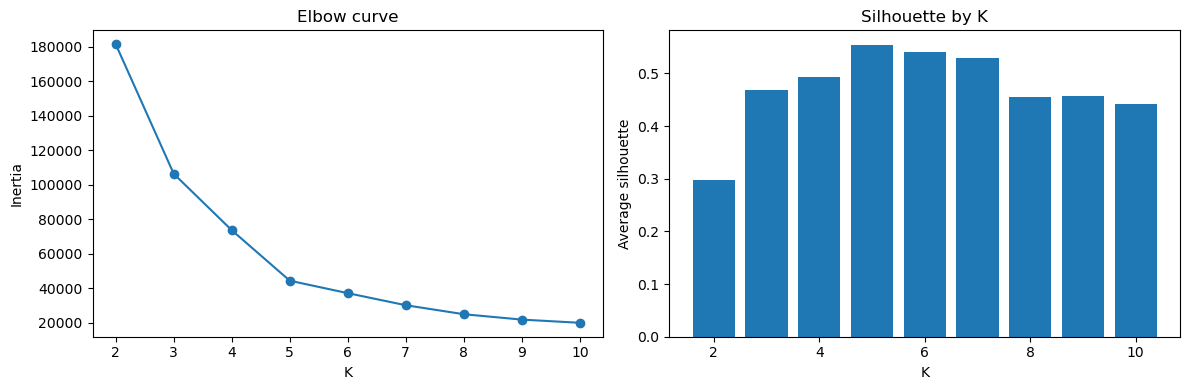

K with highest silhouette: 5


In [13]:
# Part 2 — Choosing K: Elbow and Silhouette
# Task 2.1 — Elbow and silhouette for K = 2 to 10
rows = []
for k in range(2, 11):
    km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(X2)
    rows.append((k, km.inertia_, silhouette_score(X2, km.labels_)))
t2 = pd.DataFrame(rows, columns=["K", "Inertia", "Silhouette"])
display(t2.round(4))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(t2.K, t2.Inertia, marker="o"); ax[0].set_xlabel("K"); ax[0].set_ylabel("Inertia"); ax[0].set_title("Elbow curve")
ax[1].bar(t2.K, t2.Silhouette); ax[1].set_xlabel("K"); ax[1].set_ylabel("Average silhouette"); ax[1].set_title("Silhouette by K")
plt.tight_layout(); plt.show()
print("K with highest silhouette:", int(t2.loc[t2.Silhouette.idxmax(), "K"]))

Customer 1: a=24.6404, b=42.2653, s=0.4170 | sklearn: 0.4170


,count,mean,min
Cluster,,,
0,81,0.597,0.115
1,39,0.509,0.225
2,22,0.599,0.051
3,35,0.504,-0.023
4,23,0.512,-0.009


Negative silhouettes: 2


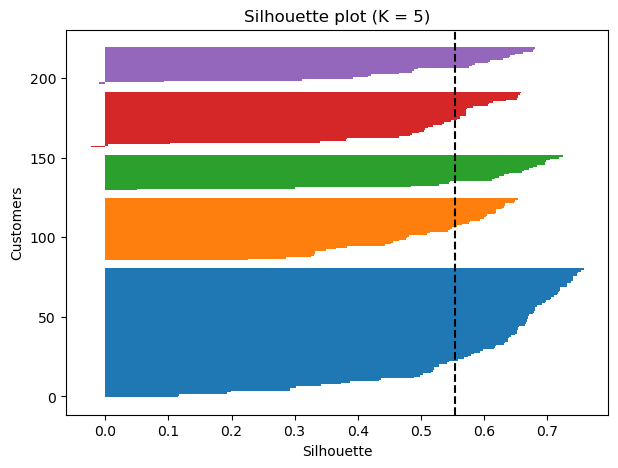

In [14]:
# Task 2.2 — Silhouette by hand 
km5 = KMeans(n_clusters=5, n_init=10, random_state=SEED).fit(X2)
lab5 = km5.labels_

def sil_point(X, labels, i):
    d = np.sqrt(((X - X[i]) ** 2).sum(axis=1))
    own = (labels == labels[i]); own[i] = False
    a = d[own].mean()
    b = min(d[labels == c].mean() for c in np.unique(labels) if c != labels[i])
    return a, b, (b - a) / max(a, b)

a, b, s = sil_point(X2.astype(float), lab5, 0)
print(f"Customer 1: a={a:.4f}, b={b:.4f}, s={s:.4f} | sklearn: {silhouette_samples(X2, lab5)[0]:.4f}")

sam = silhouette_samples(X2, lab5)
display(pd.DataFrame({"Cluster": lab5, "s": sam}).groupby("Cluster").s.agg(["count", "mean", "min"]).round(3))
print("Negative silhouettes:", (sam < 0).sum())

# silhouette plot
y0 = 0
plt.figure(figsize=(7, 5))
for c in range(5):
    sc = np.sort(sam[lab5 == c])
    plt.barh(range(y0, y0 + len(sc)), sc, height=1.0)
    y0 += len(sc) + 5
plt.axvline(sam.mean(), color="k", linestyle="--"); plt.xlabel("Silhouette"); plt.ylabel("Customers")
plt.title("Silhouette plot (K = 5)"); plt.show()

In [15]:
# Task 2.3 — The lecture practice problem 
pts = np.array([1, 3, 5, 7, 11, 13, 15], float)
lp, Cp, Ip, n_ = my_kmeans(pts, [1, 11])
print("Clusters:", lp.tolist(), "| Centroids:", Cp.ravel(), "| Inertia:", Ip, "| Iterations:", n_)
sp = silhouette_samples(pts.reshape(-1, 1), lp)
for v in [1, 7, 11]:
    i = int(np.where(pts == v)[0][0])
    a, b, s = sil_point(pts.reshape(-1, 1), lp, i)
    print(f"Point {v}: a={a}, b={b}, s={s:.4f} | sklearn {sp[i]:.4f}")

Clusters: [0, 0, 0, 0, 1, 1, 1] | Centroids: [ 4. 13.] | Inertia: 28.0 | Iterations: 3
Point 1: a=4.0, b=12.0, s=0.6667 | sklearn 0.6667
Point 7: a=4.0, b=6.0, s=0.3333 | sklearn 0.3333
Point 11: a=3.0, b=7.0, s=0.5714 | sklearn 0.5714


In [16]:
# (a) Which K does the elbow suggest and which K does the silhouette suggest? Do they agree? Quote the 
# numbers (for example how much the inertia drops from K=4 to 5 and from 5 to 6). 
# Both choose K = 5. The inertia drops 29,231 from K = 4 to 5 (73,680 to 44,448) but only 7,215 from K = 5 to 6, so the elbow is
# at 5, and the silhouette peaks at 0.554 at K = 5.
# (b) What is the silhouette of customer 1 and what does it tell you? Which cluster has the weakest average 
# silhouette and how many customers have a negative value? 
# Customer 1 has s = 0.417: moderately well placed, not clearly inside its cluster. The weakest average is cluster 3 (0.504), 
# and 2 customers are negative.
# (c) In the practice problem, is point 1 or point 7 less well placed? Explain using a and b. 
# Point 7 is less well placed (0.333 vs 0.667): its a (4) is close to its b (6), so it is only slightly nearer its own cluster
# than the other.
# (d) Why should we never choose K only by the lowest inertia? 
# Inertia always falls as K grows, reaching 0 at K = number of points, so the lowest inertia would always choose the largest K.

,Setting,Distinct inertia,Lowest,Highest,% reached best
0,random n_init=1,14,44448.46,91761.98,33.3
1,k-means++ n_init=1,6,44448.46,66733.44,60.0
2,k-means++ n_init=10,1,44448.46,44448.46,100.0


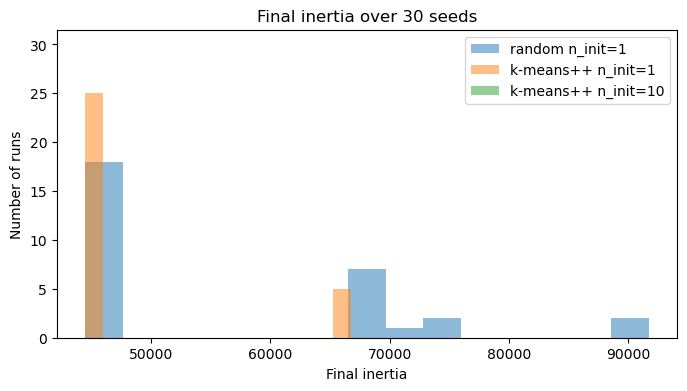

In [17]:
# Part 3 — Starting Points and Stability
# Task 3.1 — 30 different seeds
settings = {"random n_init=1": dict(init="random", n_init=1),
            "k-means++ n_init=1": dict(init="k-means++", n_init=1),
            "k-means++ n_init=10": dict(init="k-means++", n_init=10)}
res = {nm: [KMeans(n_clusters=5, random_state=s, **kw).fit(X2) for s in range(30)]
       for nm, kw in settings.items()}

best = min(r.inertia_ for runs in res.values() for r in runs)
tab = []
for nm, runs in res.items():
    I = np.array([r.inertia_ for r in runs])
    tab.append((nm, len(set(I.round(1))), I.min().round(2), I.max().round(2),
                round((I.round(1) == round(best, 1)).mean() * 100, 1)))
display(pd.DataFrame(tab, columns=["Setting", "Distinct inertia", "Lowest", "Highest", "% reached best"]))

plt.figure(figsize=(8, 4))
for nm, runs in res.items():
    plt.hist([r.inertia_ for r in runs], bins=15, alpha=0.5, label=nm)
plt.xlabel("Final inertia"); plt.ylabel("Number of runs"); plt.title("Final inertia over 30 seeds")
plt.legend(); plt.show()

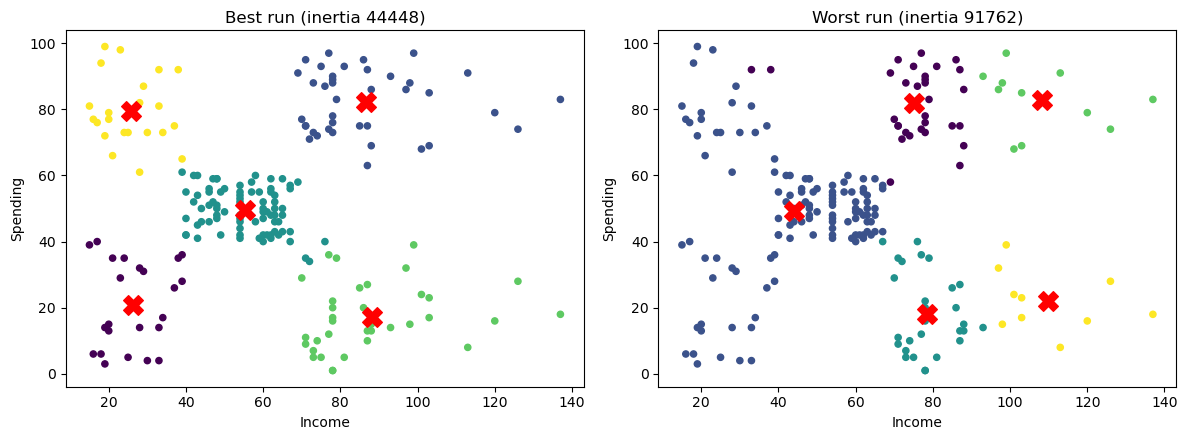

ARI best vs worst: 0.4553


In [18]:
# Task 3.2 — Best run vs worst run
rr = res["random n_init=1"]
bi = min(rr, key=lambda r: r.inertia_); wi = max(rr, key=lambda r: r.inertia_)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
for a, mdl, t in zip(ax, [bi, wi], ["Best run", "Worst run"]):
    a.scatter(X2[:, 0], X2[:, 1], c=mdl.labels_, s=20)
    a.scatter(*mdl.cluster_centers_.T, c="red", marker="X", s=200)
    a.set_xlabel("Income"); a.set_ylabel("Spending"); a.set_title(f"{t} (inertia {mdl.inertia_:.0f})")
plt.tight_layout(); plt.show()
print("ARI best vs worst:", round(adjusted_rand_score(bi.labels_, wi.labels_), 4))

In [19]:
# (a) How many different final inertia values did the random-start setting produce, and what percentage of its 
# runs reached the best one? Compare with the other two settings.
# Random starts produced 14 different inertia values, and only 33.3% of the runs reached the best, against 60% for k-means++
# (n_init=1) and 100% for k-means++ with n_init=10
# (b) Why can the same data and the same K give different answers? 
# Different starting centroids lead the assign/update loop to different local minima, so the same data and K can give differentanswers.
# (c) How do k-means++ and n_init help? What did n_init=10 give in your table? 
# k-means++ picks far-apart starting centroids, and n_init=10 tries 10 starts and keeps the lowest inertia. Together they 
# reached the best answer in all 30 runs.
# (d) Why do we use ARI to compare two clusterings instead of comparing the label numbers directly? 
# ARI ignores cluster numbers (cluster 2 in one run may be cluster 4 in another), so comparing label numbers directly would be
# meaningless.

ARI raw k$ vs raw $      : 0.4897
ARI scaled k$ vs scaled $: 1.0
ARI raw $ vs scaled $    : 0.3605


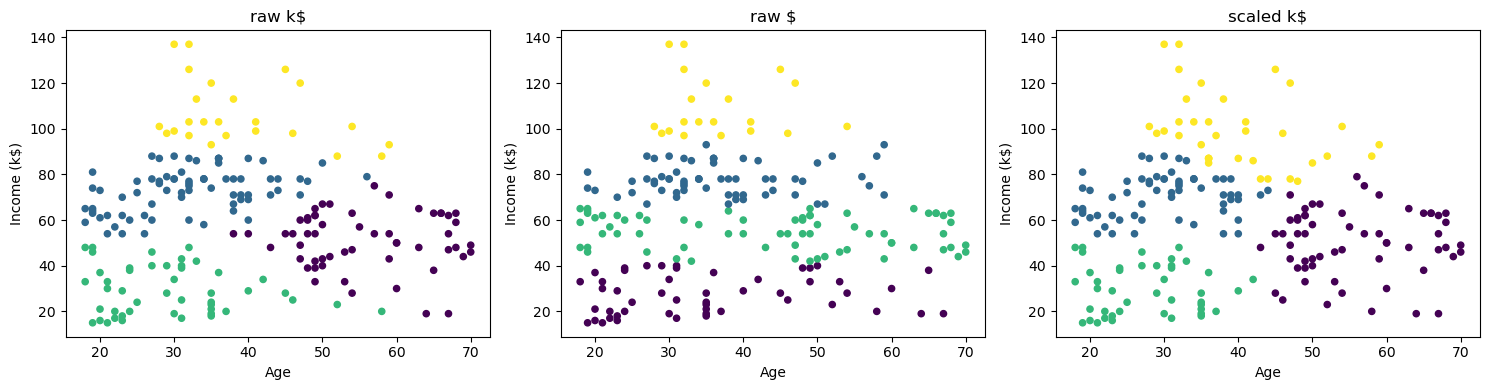

In [20]:
# Part 4 — Scaling: Units Decide the Clusters
# Task 4.1 — Change the unit, change the clusters 
Xa = df[["Age", "Income"]].values.astype(float)
Xd = Xa.copy(); Xd[:, 1] *= 1000                        # Income in dollars
def fit(X, k=4): return KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(X).labels_
L = {"raw k$": fit(Xa), "raw $": fit(Xd),
     "scaled k$": fit(StandardScaler().fit_transform(Xa)),
     "scaled $": fit(StandardScaler().fit_transform(Xd))}
print("ARI raw k$ vs raw $      :", round(adjusted_rand_score(L["raw k$"], L["raw $"]), 4))
print("ARI scaled k$ vs scaled $:", round(adjusted_rand_score(L["scaled k$"], L["scaled $"]), 4))
print("ARI raw $ vs scaled $    :", round(adjusted_rand_score(L["raw $"], L["scaled $"]), 4))

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, nm in zip(ax, ["raw k$", "raw $", "scaled k$"]):
    a.scatter(Xa[:, 0], Xa[:, 1], c=L[nm], s=20)
    a.set_xlabel("Age"); a.set_ylabel("Income (k$)"); a.set_title(nm)
plt.tight_layout(); plt.show()

In [21]:
# Task 4.2 — Wine data: raw vs scaled 
w = load_wine(); Xw, yw = w.data, w.target
sd = pd.Series(Xw.std(axis=0), index=w.feature_names).sort_values(ascending=False)
print("Largest std:\n", sd.head(3).round(2), "\nSmallest std:\n", sd.tail(1).round(3))

Xws = StandardScaler().fit_transform(Xw)
wine_res = {}
for nm, X in [("raw", Xw), ("scaled", Xws)]:
    km = KMeans(n_clusters=3, n_init=10, random_state=SEED).fit(X)
    wine_res[nm] = km.labels_
    print(nm, "| ARI:", round(adjusted_rand_score(yw, km.labels_), 4),
          "| silhouette:", round(silhouette_score(X, km.labels_), 4),
          "| sizes:", np.bincount(km.labels_).tolist())

Largest std:
 proline              314.02
magnesium             14.24
alcalinity_of_ash      3.33
dtype: float64 
Smallest std:
 nonflavanoid_phenols    0.124
dtype: float64
raw | ARI: 0.3711 | silhouette: 0.5711 | sizes: [62, 47, 69]
scaled | ARI: 0.8975 | silhouette: 0.2849 | sizes: [65, 51, 62]


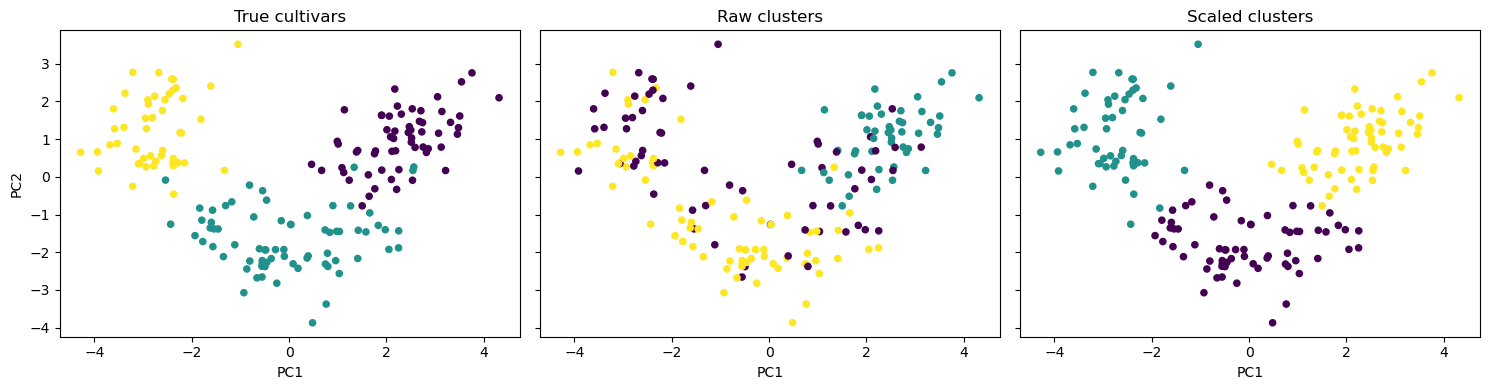

In [22]:
# Task 4.3 — Draw it 
Z = PCA(n_components=2, random_state=SEED).fit_transform(Xws)
fig, ax = plt.subplots(1, 3, figsize=(15, 4), sharex=True, sharey=True)
for a, (t, c) in zip(ax, [("True cultivars", yw), ("Raw clusters", wine_res["raw"]), ("Scaled clusters", wine_res["scaled"])]):
    a.scatter(Z[:, 0], Z[:, 1], c=c, s=20); a.set_title(t); a.set_xlabel("PC1")
ax[0].set_ylabel("PC2"); plt.tight_layout(); plt.show()

In [23]:
# (a) What happened when only the unit of Income changed? Explain it with the distance formula (which feature controls the distance now?).
# Changing only the unit changed the clusters (ARI 0.49). In dollars, Income’s numbers are 1000 times bigger, so in √((ΔAge)² +
# (ΔIncome)²) the Income term alone controls the distance and Age is almost ignored. After scaling, the unit no longer matters(ARI 1.0).
# (b) On the Wine data which feature dominated the raw distance and how big is its standard deviation compared 
# with the others? What were the ARI values raw vs scaled? 
# proline (std 314) dominates the distance, since the next feature has std 14. ARI rises from 0.371 (raw) to 0.898 (scaled).
# (c) The silhouette was higher on the raw Wine data although the clustering was worse. Explain why a silhouette 
# can mislead here and why comparing it between raw and scaled data is not fair. 
# (d) In a real project with no labels, how will you decide whether to scale? Write your rule in one or two sentences.
# Scale whenever the features have different units or very different ranges, unless the raw scale itself carries meaning. 
# Check by comparing the std of the features.

Sizes without: [81, 39, 22, 35, 23] | with: [100, 1, 23, 39, 38]
Centroids without (sorted by income):
 [[25.7 79.4]
 [26.3 20.9]
 [55.3 49.5]
 [86.5 82.1]
 [88.2 17.1]]
Centroids with (sorted by income):
 [[ 26.3  20.9]
 [ 48.3  56.5]
 [ 86.5  82.1]
 [ 87.   18.6]
 [400.   99. ]]
ARI on original 200: 0.7532


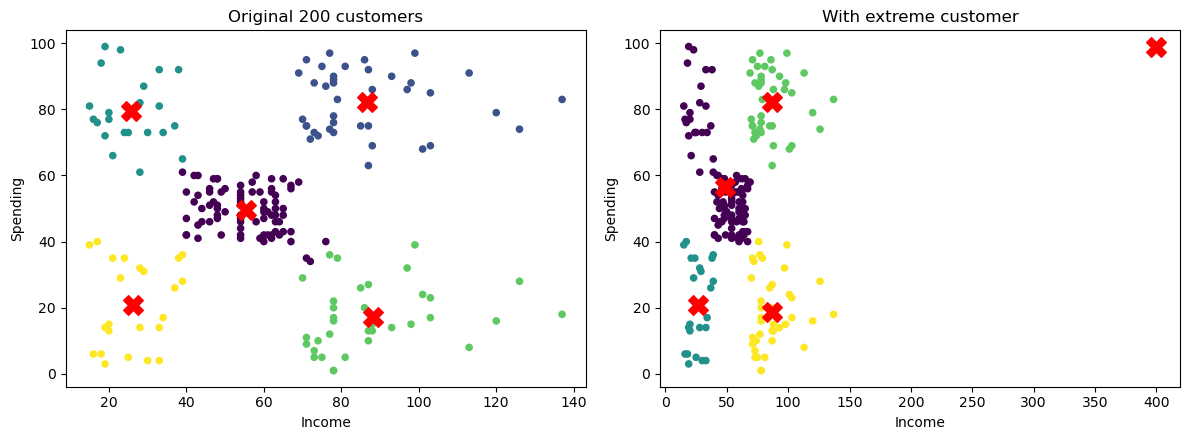

In [24]:
# Part 5 — Outliers and Anomalies
# Task 5.1 — One extreme customer
X2e = np.vstack([X2, [400, 99]])
m0 = KMeans(n_clusters=5, n_init=10, random_state=SEED).fit(X2)
m1 = KMeans(n_clusters=5, n_init=10, random_state=SEED).fit(X2e)
print("Sizes without:", np.bincount(m0.labels_).tolist(), "| with:", np.bincount(m1.labels_).tolist())
print("Centroids without (sorted by income):\n", m0.cluster_centers_[np.argsort(m0.cluster_centers_[:, 0])].round(1))
print("Centroids with (sorted by income):\n", m1.cluster_centers_[np.argsort(m1.cluster_centers_[:, 0])].round(1))
print("ARI on original 200:", round(adjusted_rand_score(m0.labels_, m1.labels_[:200]), 4))

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].scatter(X2[:, 0], X2[:, 1], c=m0.labels_, s=20); ax[0].scatter(*m0.cluster_centers_.T, c="red", marker="X", s=200)
ax[1].scatter(X2e[:, 0], X2e[:, 1], c=m1.labels_, s=20); ax[1].scatter(*m1.cluster_centers_.T, c="red", marker="X", s=200)
for a, t in zip(ax, ["Original 200 customers", "With extreme customer"]):
    a.set_xlabel("Income"); a.set_ylabel("Spending"); a.set_title(t)
plt.tight_layout(); plt.show()

In [25]:
# Task 5.2 — Catch it and repair 
d = m0.transform(X2).min(axis=1)                       # distance to nearest centroid
thr = d.mean() + 3 * d.std()
dx = m0.transform([[400, 99]]).min()
flag = d > thr
print("Threshold:", round(thr, 2), "| Real customers flagged:", flag.sum())
print("Extra customer distance:", round(dx, 2), "| flagged:", dx > thr)

out = df.assign(Cluster=m0.labels_, Distance=d.round(2)).sort_values("Distance", ascending=False).head(5)
display(out[["CustomerID", "Age", "Income", "Spending", "Cluster", "Distance"]])

mr = KMeans(n_clusters=5, n_init=10, random_state=SEED).fit(X2[~flag])
print("Repaired sizes:", np.bincount(mr.labels_).tolist())
print("ARI vs original model:", round(adjusted_rand_score(m0.labels_, mr.predict(X2)), 4))

Threshold: 34.8 | Real customers flagged: 4
Extra customer distance: 313.92 | flagged: True


,CustomerID,Age,Income,Spending,Cluster,Distance
199,200,30,137,83,1,50.47
198,199,32,137,18,3,48.81
197,198,32,126,74,1,40.29
196,197,45,126,28,3,39.34
195,196,35,120,79,1,33.61


Repaired sizes: [80, 34, 23, 37, 22]
ARI vs original model: 0.9847


In [26]:
# (a) What did the single extreme customer do to the clusters? Which real groups were affected? Use sizes and centroids.
# The single customer took one whole cluster for itself (size 1). The other 199 customers were then split into only four groups:
# the Mid group (81) and the Low-income/High-spending group (22) merged into one cluster of 100, and the cluster centroids moved
# (the High-income/Low-spending group went from (88.2, 17.1) to (87.0, 18.6)).
# (b) How well did the rule detect the extra customer? The rule also flagged some real customers: are they 
# mistakes in the data or something worth looking at? Look at their Income and Spending. 
# The rule caught the extra customer easily (313.92 vs threshold 34.80). The 4 flagged real customers all have very high incomes
# (126k to 137k). They are not data errors but real wealthy customers, worth investigating (for example for premium offers).
# (c) Name two ways to deal with outliers and one risk of simply deleting them. 
# Ways to deal with outliers: remove them, cap or transform them (for example log), use a more robust method, or cluster them
# separately as their own group. The risk of deleting them is that you lose valuable real customers.

In [27]:
# Part 6 — From Clusters to Customer Segments
# Task 6.1 — Profile and name the segments
df["Cluster"] = m0.labels_                              # the original 200 customers, K = 5
prof = df.groupby("Cluster").agg(
    n=("Age", "size"), Age=("Age", "mean"), Income=("Income", "mean"),
    Spending=("Spending", "mean"),
    Female_pct=("Gender", lambda g: (g == "Female").mean() * 100)).round(1).sort_values("Income")
display(prof)

def lvl(v, lo, hi): return "Low" if v < lo else ("High" if v >= hi else "Mid")
names = {c: f"{lvl(r.Income, 40, 70)} income / {lvl(r.Spending, 35, 65)} spending" for c, r in prof.iterrows()}
df["Segment"] = df["Cluster"].map(names)
print(df["Segment"].value_counts())

,n,Age,Income,Spending,Female_pct
Cluster,,,,,
2,22,25.3,25.7,79.4,59.1
4,23,45.2,26.3,20.9,60.9
0,81,42.7,55.3,49.5,59.3
1,39,32.7,86.5,82.1,53.8
3,35,41.1,88.2,17.1,45.7


Segment
Mid income / Mid spending      81
High income / High spending    39
High income / Low spending     35
Low income / Low spending      23
Low income / High spending     22
Name: count, dtype: int64


In [28]:
# Task 6.2 — Does Gender matter? Does Age matter?
ct = pd.crosstab(df["Segment"], df["Gender"], normalize="index").mul(100).round(1)
display(ct)
print("Overall % female:", round((df["Gender"] == "Female").mean() * 100, 1))

X3 = StandardScaler().fit_transform(df[["Age", "Income", "Spending"]])
s3 = {k: silhouette_score(X3, KMeans(n_clusters=k, n_init=10, random_state=SEED).fit_predict(X3)) for k in range(2, 9)}
print({k: round(v, 4) for k, v in s3.items()})

Gender,Female,Male
Segment,,
High income / High spending,53.8,46.2
High income / Low spending,45.7,54.3
Low income / High spending,59.1,40.9
Low income / Low spending,60.9,39.1
Mid income / Mid spending,59.3,40.7


Overall % female: 56.0
{2: 0.3355, 3: 0.3578, 4: 0.404, 5: 0.4166, 6: 0.4284, 7: 0.4172, 8: 0.4082}


In [29]:
# Task 6.3 — A three-feature alternative 
bk = max(s3, key=s3.get)
k3 = KMeans(n_clusters=bk, n_init=10, random_state=SEED).fit(X3)
df["Cluster3"] = k3.labels_
display(df.groupby("Cluster3").agg(n=("Age", "size"), Age=("Age", "mean"), Income=("Income", "mean"),
                                   Spending=("Spending", "mean")).round(1).sort_values("Age"))
print("Best K:", bk, "| ARI 3-feature vs 2-feature:", round(adjusted_rand_score(df["Cluster"], df["Cluster3"]), 4))

,n,Age,Income,Spending
Cluster3,,,,
4,23,25.0,25.3,77.6
1,39,26.8,57.1,48.1
3,39,32.7,86.5,82.1
2,33,41.9,88.9,17.0
5,21,45.5,26.3,19.4
0,45,56.3,54.3,49.1


Best K: 6 | ARI 3-feature vs 2-feature: 0.7002


In [31]:
# (a) Give each of the 5 segments a short business name and one concrete action (an offer or a message). Use the numbers from your profile table. 
# -> Low income / High spending (22): young “enthusiasts”. Offer student or budget loyalty rewards and trendy low-price items.
# -> Low income / Low spending (23): price-sensitive. Send discount and clearance coupons.
# -> Mid income / Mid spending (81): the average majority. Run general promotions and a loyalty program.
# -> High income / High spending (39): premium customers. Give VIP perks and early access.
# -> High income / Low spending (35): wealthy but unengaged. Send personalised premium offers.
# (b) Which segment is the most valuable now and which one is the biggest opportunity? Why?
# The most valuable now is High income / High spending (income 86.5, spending 82.1). The biggest opportunity is High income / 
# Low spending: 35 customers with income 88.2 but spending of only 17.1, so any increase in spending is large.
# (c) Does Gender help to separate the segments? Quote the percentages.
# ) Gender barely separates the segments. Women are 45.7% to 60.9% of the segments against 56.0% overall, with only High income 
# / Low spending leaning male (54.3% male).
# (d) Does adding Age change the story? Which segmentation would you present and why? (Careful: silhouette 
# values from different feature sets are not directly comparable.) 
# Adding Age splits the Mid group by age (a 26.8-year-old group at 57k income and a 56.3-year-old group at 54k), a story the
# income/spending view can’t tell. I’d present the 2-feature K = 5 version for its simplicity and easy names, and mention the
# age split as an extra insight. The silhouettes (0.554 vs 0.428) come from different feature sets, so they aren’t directlycomparable.

In [32]:
# Part 7 — Final Output and Wrap-Up
# Task 7.1 — Save the segments
out = df[["CustomerID", "Age", "Gender", "Income", "Spending", "Cluster", "Segment"]]
out.to_csv("customer_segments.csv", index=False)
print(out["Segment"].value_counts())

Segment
Mid income / Mid spending      81
High income / High spending    39
High income / Low spending     35
Low income / Low spending      23
Low income / High spending     22
Name: count, dtype: int64


In [33]:
# Summary: K-Means uses distances, so features with bigger numbers dominate.
# Changing Income from k$ to dollars changed the clusters (ARI 0.49). After scaling, the unit didn’t matter (ARI 1.0).
# On Wine, proline (std 314) swamped everything else. Scaling raised ARI from 0.37 to 0.90.
# The raw silhouette (0.57) looked better than the scaled one (0.28), but the raw clusters were worse, so don’t trust a silhouette across different scales.
# Rule: scale when features have different units or ranges.

In [ ]:
# (a) What was the most surprising result in this lab? 
# (a) Candidate surprises from my run: one extra customer reduced the real structure to four clusters; random starts reached 
# the best result only 33% of the time; the raw Wine silhouette was higher (0.571) even though the clustering was much worse 
# (ARI 0.37 vs 0.90).
# (b) If you had one more hour, what would you try next? 
# Ideas for one more hour: test a robust method (such as DBSCAN) against K-Means, or check how stable the segments are with
# repeated samples.